# Training YOLOv8 — Final Project Oprec PENSHIP

Notebook dasar untuk melatih model deteksi `bottle`, `laptop`, dan `pencil` di Google Colab.
Jalankan cell dari atas ke bawah (**Shift + Enter**). Kode ini sengaja dibuat dasar dan **wajib dikembangkan oleh peserta** (lihat bagian Pengembangan kode di guidebook).

## 1. Aktifkan GPU

Menu **Runtime → Change runtime type → T4 GPU → Save**, lalu jalankan cell di bawah.
Apabila muncul tabel berisi nama GPU (misalnya Tesla T4), GPU sudah aktif.

In [ ]:
!nvidia-smi

Mon Oct 26 09:42:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   70C    P0             29W /   70W |    1775MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Install library

In [ ]:
%pip install -q "ultralytics>=8.3.0" "roboflow>=1.1.0"

## 3. API key Roboflow

Simpan API key di **Colab Secrets**, jangan diketik di notebook (notebook ini ikut dikumpulkan):

1. Ambil API key di https://app.roboflow.com/settings/api
2. Klik ikon kunci (**Secrets**) di panel kiri Colab → **Add new secret**.
3. Name: `ROBOFLOW_API_KEY`, Value: API key Roboflow, lalu aktifkan **Notebook access**.

Apabila secret tidak ditemukan, cell di bawah akan meminta API key lewat kotak input tersembunyi.

In [ ]:
import os

if not os.environ.get("ROBOFLOW_API_KEY"):
    try:
        from google.colab import userdata
        os.environ["ROBOFLOW_API_KEY"] = userdata.get("ROBOFLOW_API_KEY")
    except Exception:
        from getpass import getpass
        os.environ["ROBOFLOW_API_KEY"] = getpass("Roboflow API key: ")

print("API key is set.")

API key is set.


## 4. Konfigurasi

Workspace, project, dan nomor versi tertera pada URL dataset: `app.roboflow.com/<workspace>/<project>/<version>`,
atau di potongan kode saat **Download Dataset → YOLOv8 → Show download code**.

In [ ]:
# Dataset (Roboflow)
ROBOFLOW_WORKSPACE = "humdiess"  # from the dataset URL
ROBOFLOW_PROJECT = "penship-final-projects-hudi"      # from the dataset URL
ROBOFLOW_VERSION = 1                 # dataset version number on Roboflow
DATASET_DIR = "dataset"                # download destination folder

# Training
MODEL = "yolov8s.pt"  # options: yolov8n.pt or yolov8s.pt
EPOCHS = 150
IMGSZ = 640           # must stay 640, do not change
BATCH = 16            # lower to 8 on out-of-memory errors
SEED = 0

### 4. Konfigurasi

In [ ]:
# Konfigurasi Terbaik Hasil Analisis
MODEL_OPTIMAL = "yolov8s.pt" # Menggunakan arsitektur Small yang menangkap fitur lebih detail
EPOCHS_OPTIMAL = 150
IMGSZ = 640 # Wajib tetap 640
BATCH_OPTIMAL = 16
SEED_OPTIMAL = 0

# Hyperparameters Tambahan untuk Object Detection Akurasi Tinggi
OPTIMIZER_OPTIMAL = "AdamW" # Menstabilkan weight decay pada objek kecil
COS_LR_OPTIMAL = True # Gradien descent yang lebih mulus
MOSAIC_OPTIMAL = 1.0 # Menggabungkan 4 gambar acak untuk variasi background
CLOSE_MOSAIC_OPTIMAL = 10 # Mematikan mosaic pada 10 epoch terakhir agar bounding box presisi

## 5. Download dataset

Apabila folder `dataset/` sudah berisi `data.yaml`, download dilewati.

In [ ]:
from pathlib import Path

data_yaml = Path(DATASET_DIR) / "data.yaml"
if data_yaml.exists():
    print(f"Dataset already exists, skipping download: {data_yaml}")
else:
    from roboflow import Roboflow

    rf = Roboflow(api_key=os.environ["ROBOFLOW_API_KEY"])
    version = rf.workspace(ROBOFLOW_WORKSPACE).project(ROBOFLOW_PROJECT).version(ROBOFLOW_VERSION)
    dataset = version.download("yolov8", location=DATASET_DIR)
    data_yaml = Path(dataset.location) / "data.yaml"

print(data_yaml.read_text())

NameError: name 'DATASET_DIR' is not defined

## 6. Training

Dengan T4 GPU dan beberapa ratus foto, 50 epoch biasanya selesai dalam hitungan menit sampai sekitar setengah jam.

In [ ]:
from ultralytics import YOLO

model_opt = YOLO(MODEL_OPTIMAL)
model_opt.train(
    data=str(data_yaml),
    epochs=EPOCHS_OPTIMAL,
    imgsz=IMGSZ,
    batch=BATCH_OPTIMAL,
    seed=SEED_OPTIMAL,
    optimizer=OPTIMIZER_OPTIMAL,
    cos_lr=COS_LR_OPTIMAL,
    mosaic=MOSAIC_OPTIMAL,
    close_mosaic=CLOSE_MOSAIC_OPTIMAL
)

save_dir_opt = Path(model_opt.trainer.save_dir)
best_path_opt = save_dir_opt / "weights" / "best.pt"
print(f"Optimal Training Output: {save_dir_opt}")
print(f"Best Optimal Model     : {best_path_opt}")

NameError: name 'MODEL_OPTIMAL' is not defined

## 7. Lihat grafik hasil training

results.png


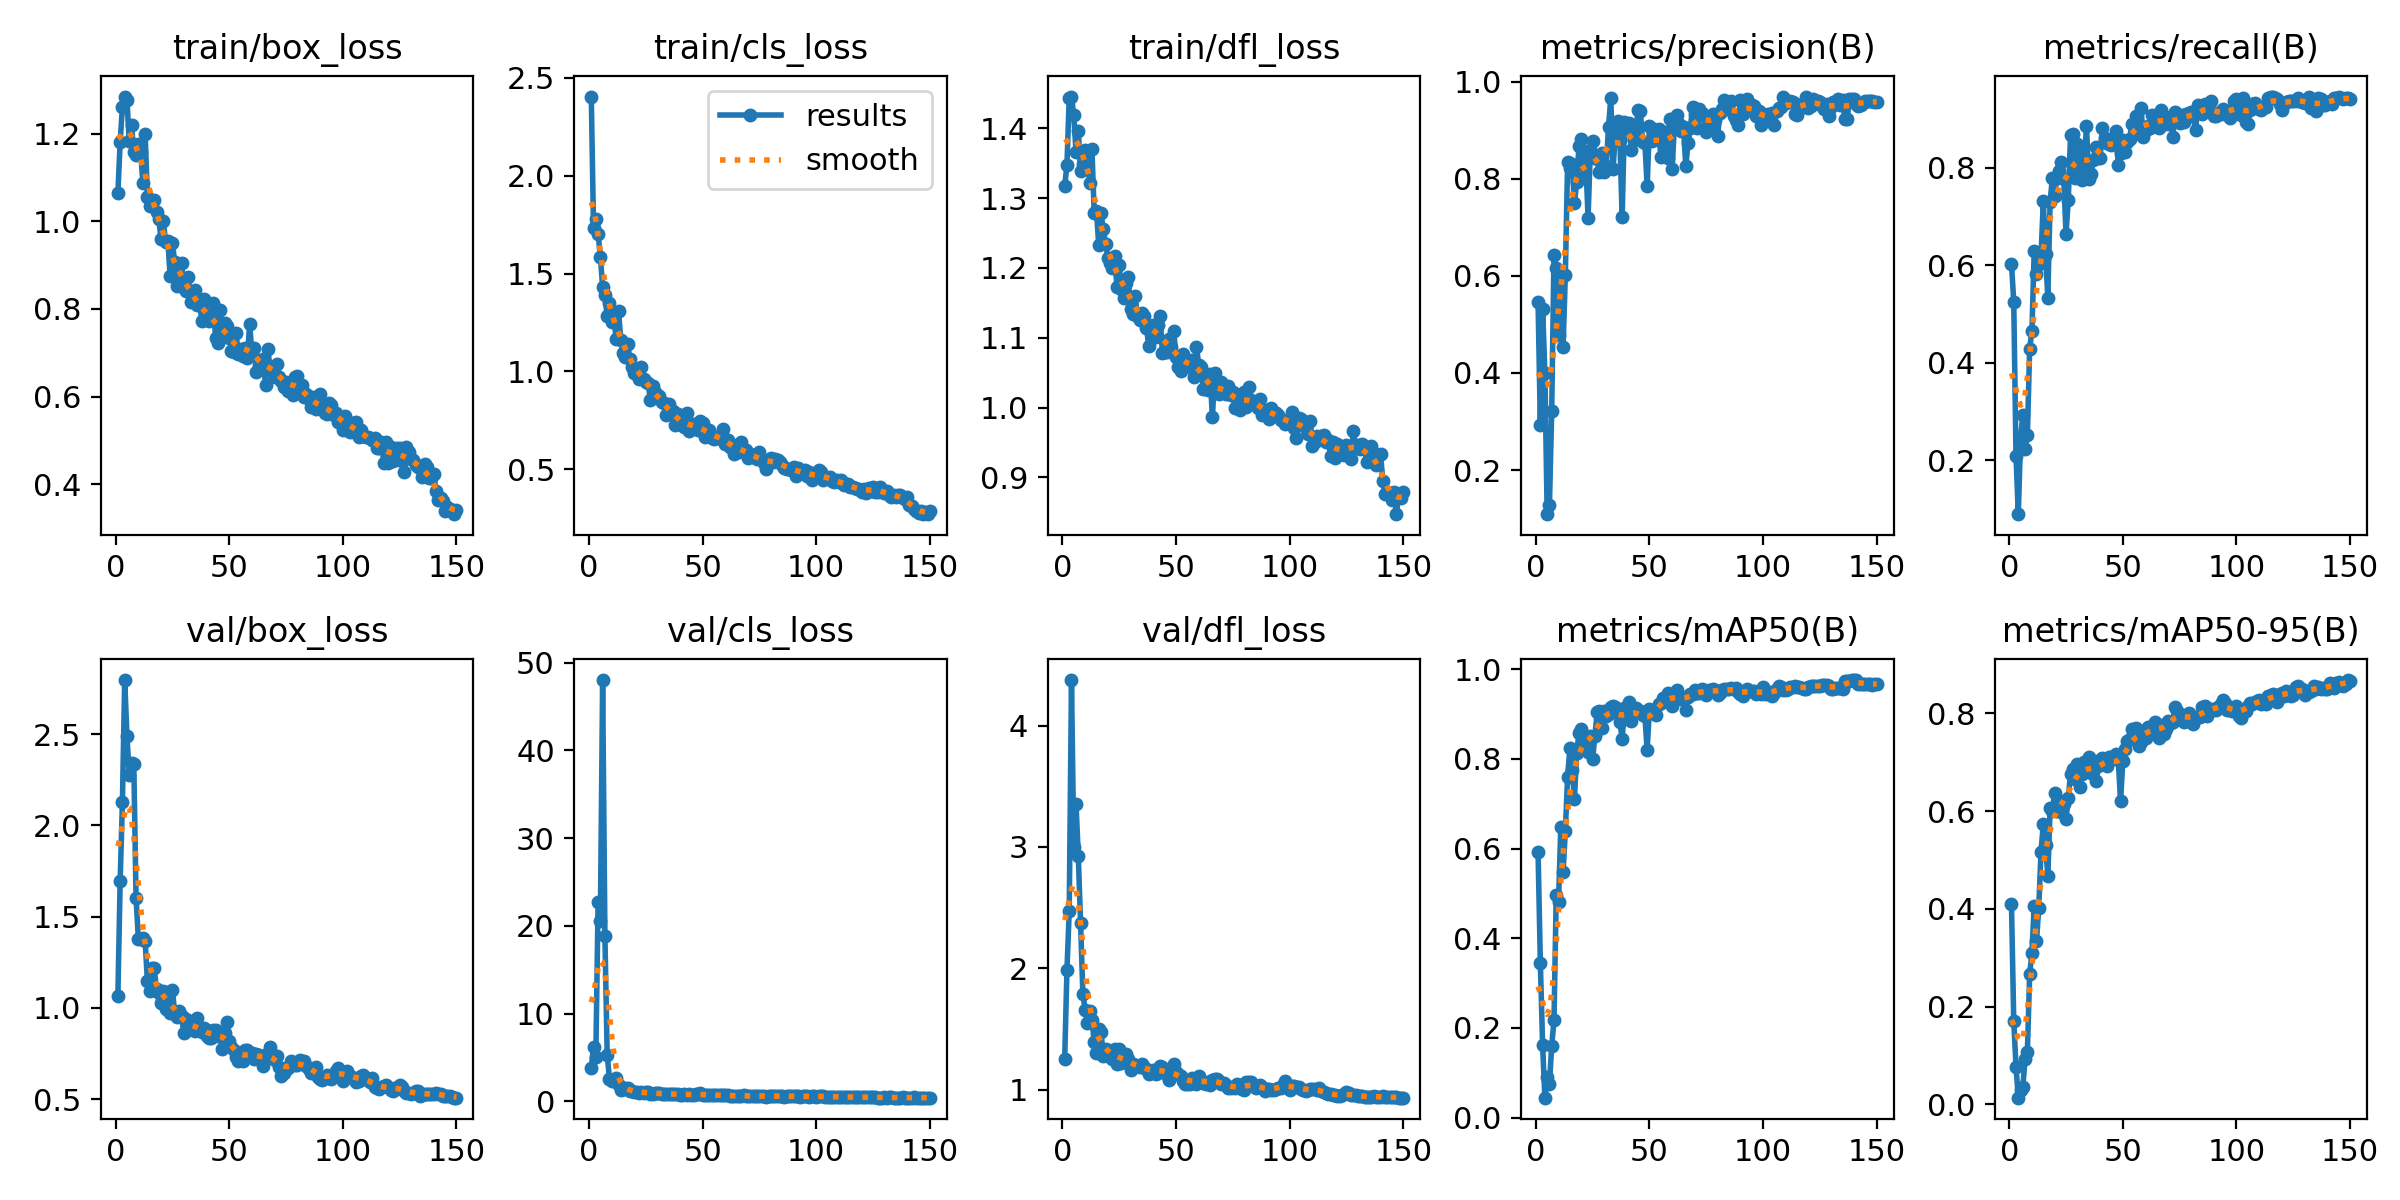

confusion_matrix.png


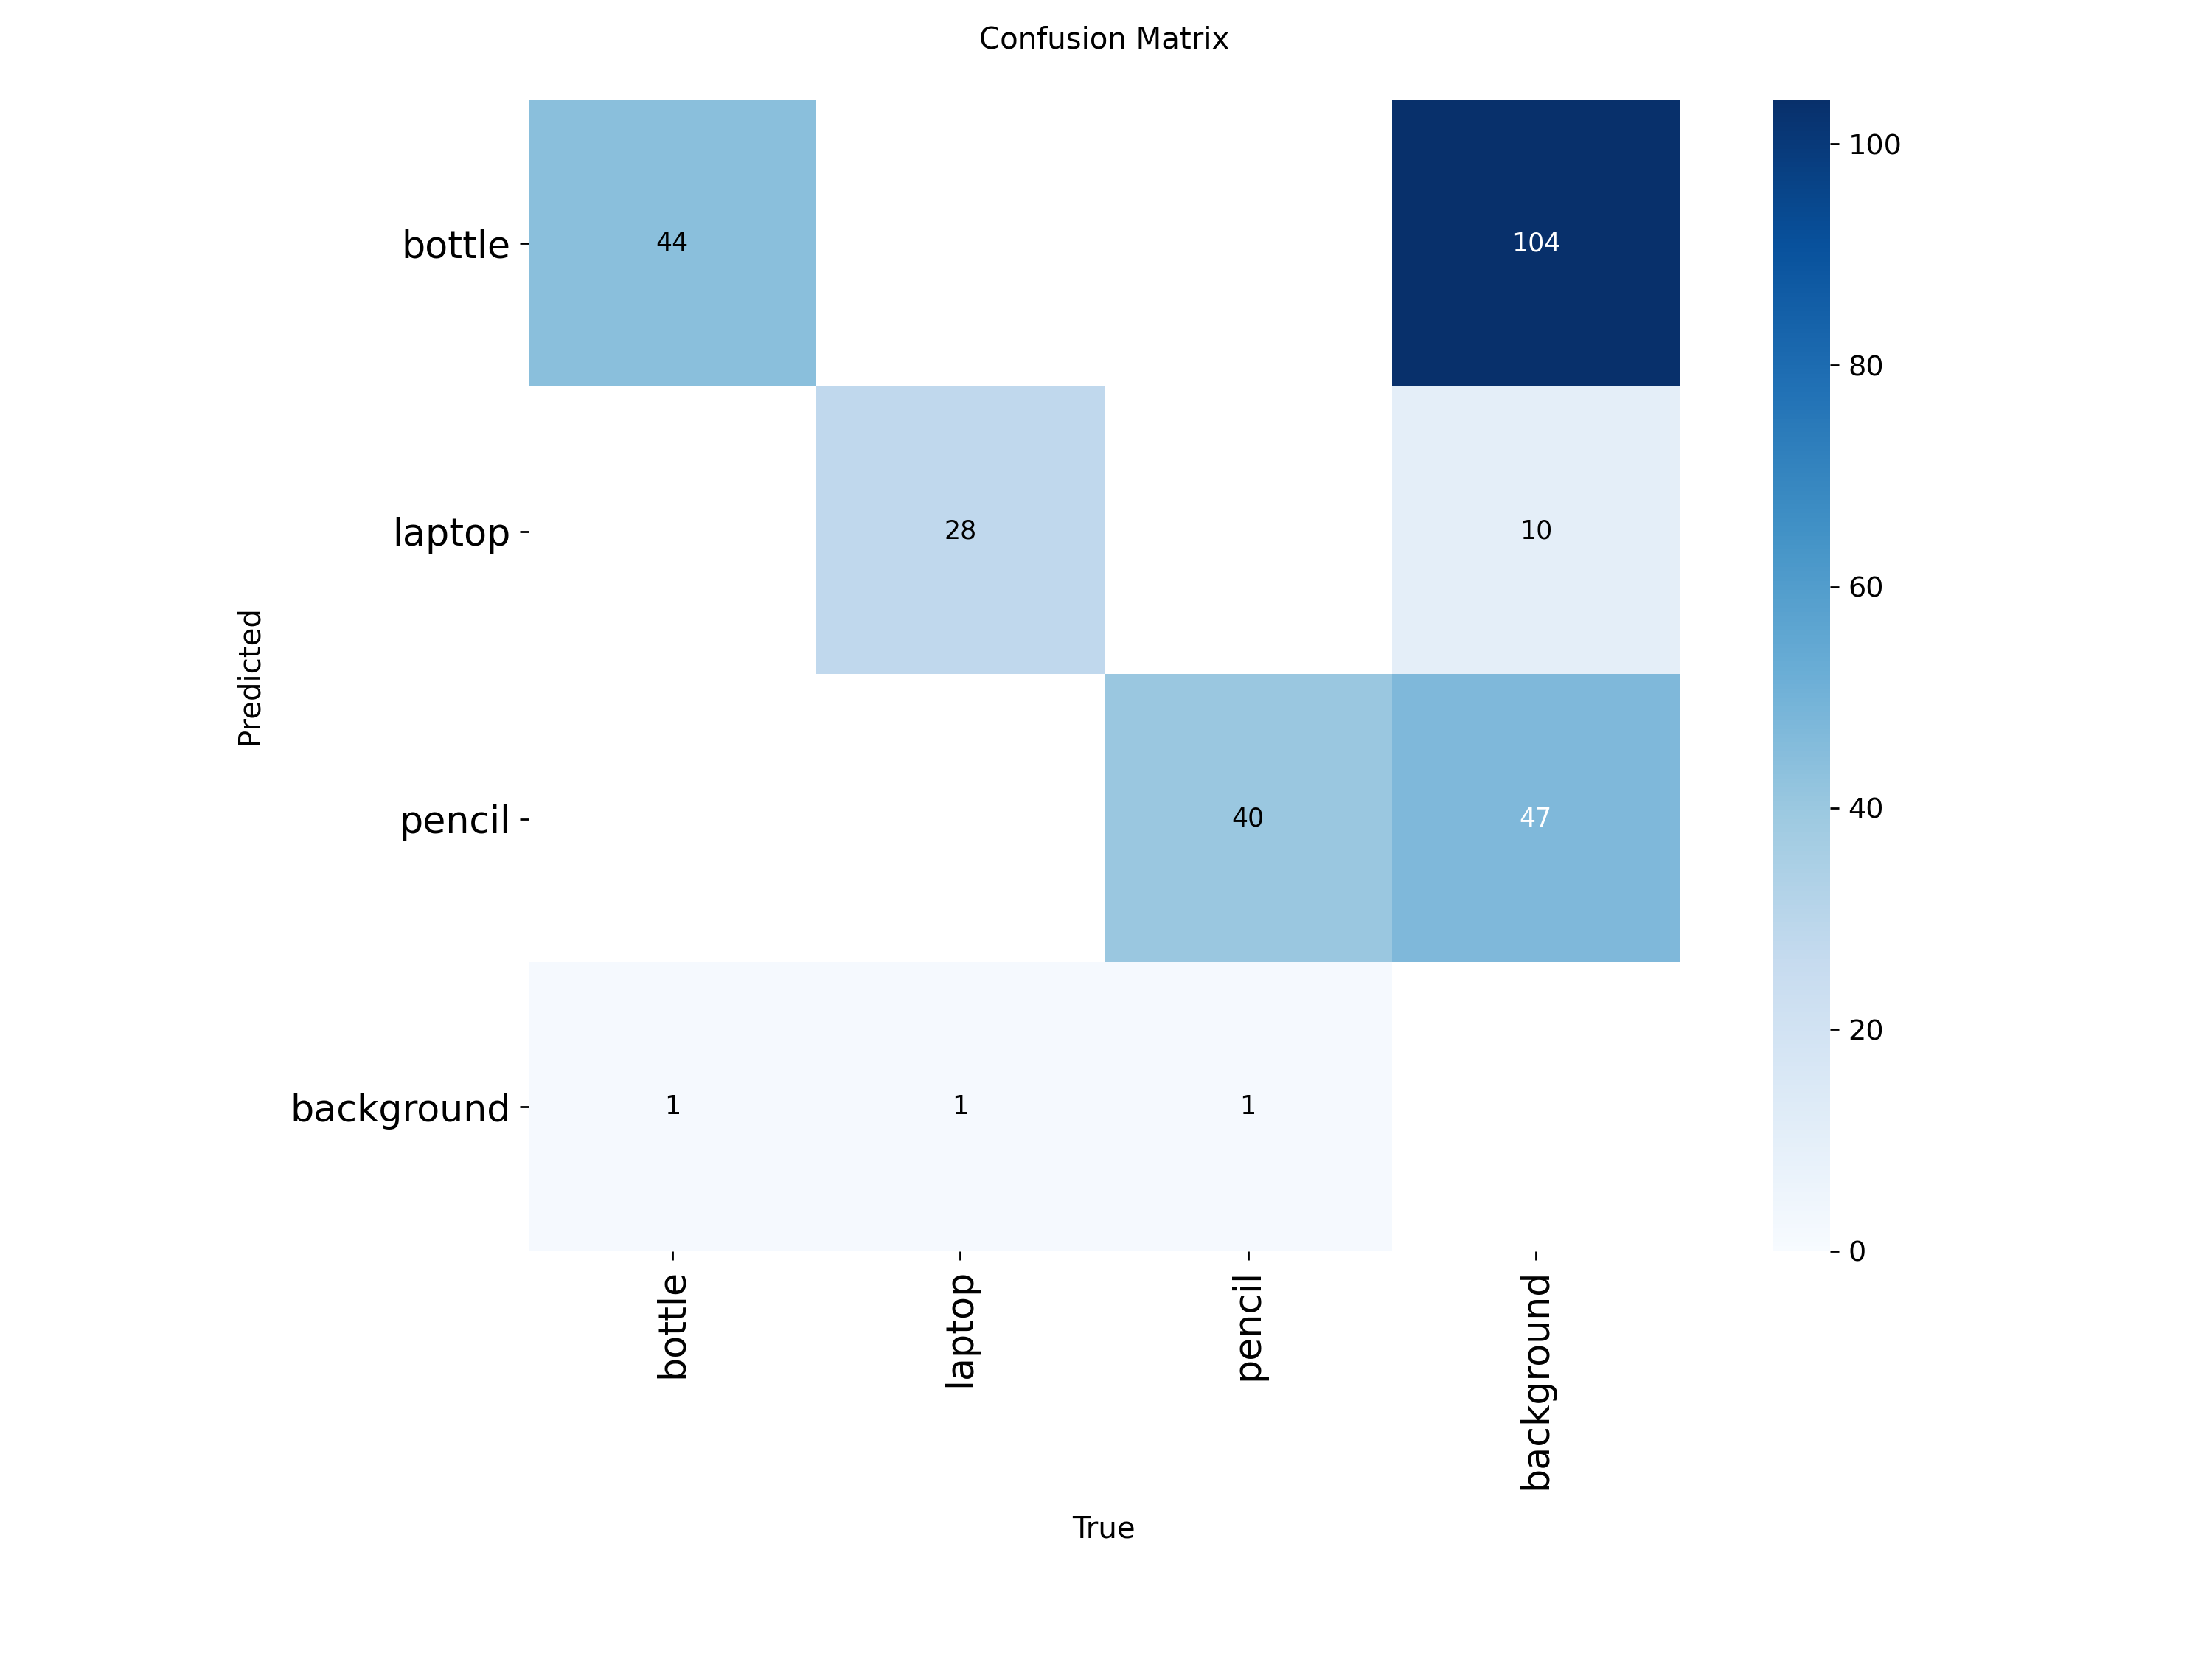

In [ ]:
from IPython.display import Image, display

for name in ["results.png", "confusion_matrix.png"]:
    path = save_dir / name
    if path.exists():
        print(name)
        display(Image(filename=str(path), width=900))

## 8. Evaluasi model terbaik di data validation

In [ ]:
best_model = YOLO(str(best_path))
metrics = best_model.val(data=str(data_yaml), imgsz=IMGSZ, conf=0.25)
print(f"mAP50-95: {metrics.box.map:.3f} | mAP50: {metrics.box.map50:.3f}")

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,126,745 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1378.6±353.3 MB/s, size: 39.6 KB)
val: Scanning /content/dataset/valid/labels.cache... 75 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 75/75 24.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.7it/s 2.9s
                   all         75        115      0.957      0.942      0.947      0.859
                bottle         40         45      0.916      0.956      0.952      0.883
                laptop         29         29      0.981      0.931      0.935      0.881
                pencil         38         41      0.975       0.94      0.953      0.813
Speed: 7.3ms preprocess, 11.1ms inference, 0.0ms loss, 5.3ms postprocess per image
Results saved to /content/runs/detect/val-4
mAP50-95: 0.8

## 9. Coba prediksi beberapa foto validation


0: 640x640 1 bottle, 21.3ms
1: 640x640 1 bottle, 21.3ms
2: 640x640 1 bottle, 21.3ms
3: 640x640 1 bottle, 21.3ms
Speed: 0.9ms preprocess, 21.3ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict-4
Prediction images saved to: /content/runs/detect/predict-4


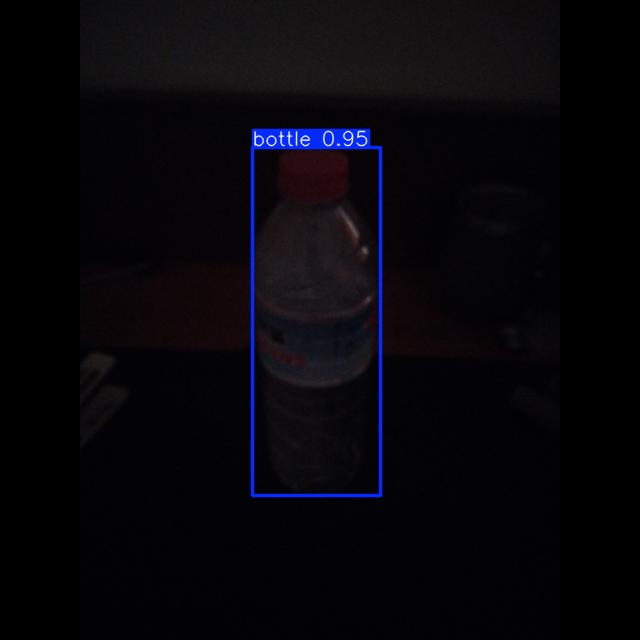

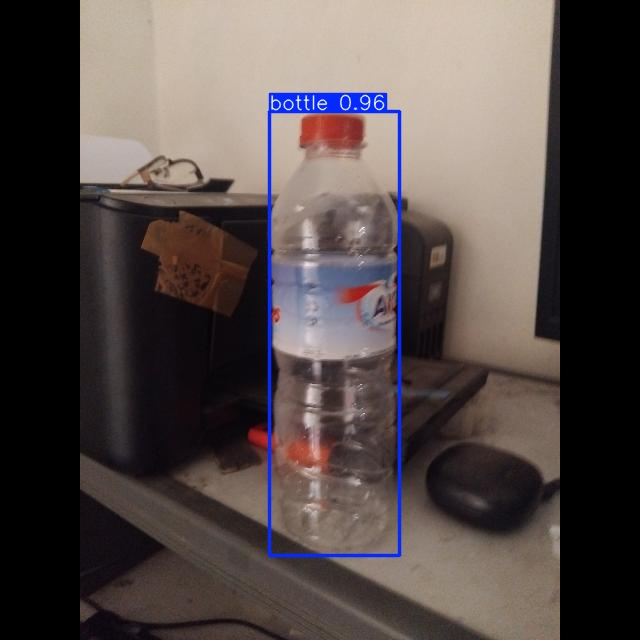

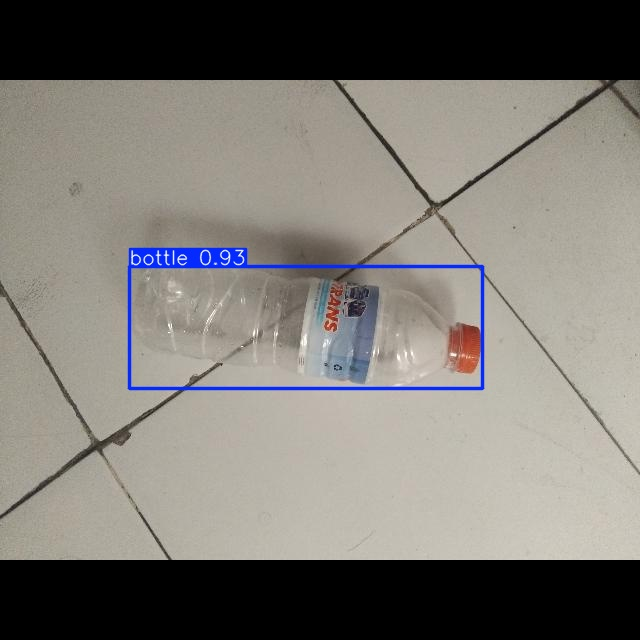

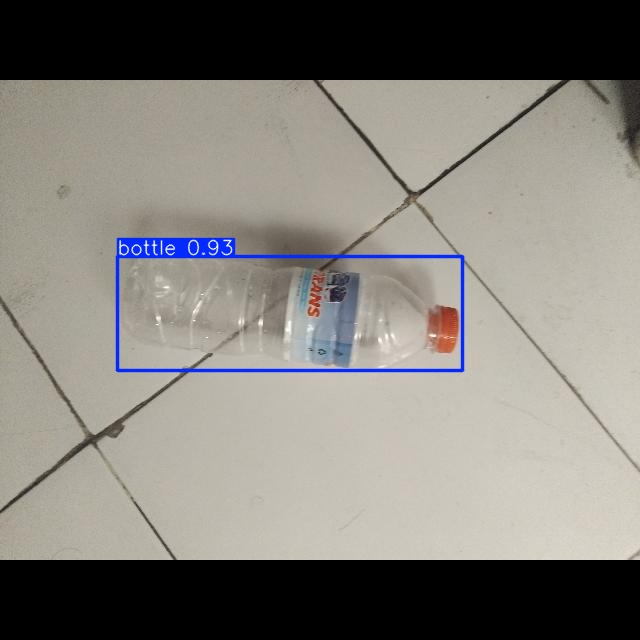

In [ ]:
valid_images = sorted((Path(DATASET_DIR) / "valid" / "images").glob("*"))[:4]
results = best_model.predict(source=[str(p) for p in valid_images], imgsz=IMGSZ, conf=0.25, save=True)
print(f"Prediction images saved to: {results[0].save_dir}")

for p in sorted(Path(results[0].save_dir).glob("*.jpg")):
    display(Image(filename=str(p), width=500))

## 10. Simpan hasil sebelum sesi Colab berakhir

File di Colab hilang saat sesi ditutup atau terputus. Cell di bawah membuat `runs.zip` (berisi `best.pt`,
`results.csv`, dan grafik) lalu men-download-nya ke laptop.

In [ ]:
import shutil

zip_path = shutil.make_archive("runs", "zip", root_dir=".", base_dir="runs")
print(f"Created: {zip_path}")

try:
    from google.colab import files
    files.download(zip_path)
    files.download(str(best_path))
except ImportError:
    print("Not running on Colab: copy the files from this folder directly.")

Created: /content/runs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

NameError: name 'best_path' is not defined